In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
DATA_PATH = Path("../data/processed/rentals_engineered.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (17890, 15)


,listing_type,category,bedrooms,bathrooms,floor_area,location,condition,region,locality,parking_space,is_furnished,lat,lng,amenities_count,price
0,rentals,Flats,2.0,2.0,145.0,"Greater Accra, East Legon",Used,Greater Accra,East Legon,0,Semi-Furnished,5.635828,-0.161359,14,9196
1,rentals,Flats,2.0,2.0,100.0,"Greater Accra, Dzorwulu",Used,Greater Accra,Dzorwulu,0,Unfurnished,5.614123,-0.195647,11,7500
2,rentals,Detached,4.0,5.0,100.0,"Greater Accra, Ashaley Botwe, Lake Side Estate",New,Greater Accra,Ashaley Botwe,0,Semi-Furnished,5.680213,-0.137248,16,11200
3,rentals,Detached,3.0,3.0,17.0,"Greater Accra, Teshie",Used,Greater Accra,Teshie,0,Semi-Furnished,5.583166,-0.104608,6,2500
4,rentals,Detached,3.0,3.0,160.0,"Greater Accra, Spintex",Used,Greater Accra,Spintex,0,Semi-Furnished,5.637614,-0.126606,14,9146


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17890 entries, 0 to 17889
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   listing_type     17890 non-null  str    
 1   category         17890 non-null  str    
 2   bedrooms         17890 non-null  float64
 3   bathrooms        17890 non-null  float64
 4   floor_area       17890 non-null  float64
 5   location         17890 non-null  str    
 6   condition        17890 non-null  str    
 7   region           17890 non-null  str    
 8   locality         17890 non-null  str    
 9   parking_space    17890 non-null  int64  
 10  is_furnished     17890 non-null  str    
 11  lat              17890 non-null  float64
 12  lng              17890 non-null  float64
 13  amenities_count  17890 non-null  int64  
 14  price            17890 non-null  int64  
dtypes: float64(5), int64(3), str(7)
memory usage: 2.0 MB

Missing values:
listing_type       0
cat

,bedrooms,bathrooms,floor_area,parking_space,lat,lng,amenities_count,price
count,17890.000000,17890.000000,17890.000000,17890.000000,17890.000000,17890.000000,17890.000000,17890.000000
mean,2.458580,2.564561,556.094913,0.000838,5.725901,-0.246623,9.721353,7999.412968
std,1.262908,1.377651,1044.912578,0.028945,0.454570,0.322523,4.167157,10404.773528
min,1.000000,1.000000,10.000000,0.000000,4.849041,-2.579248,1.000000,416.000000
25%,2.000000,1.000000,100.000000,0.000000,5.593759,-0.215087,7.000000,1700.000000
50%,2.000000,2.000000,145.000000,0.000000,5.637614,-0.161359,9.000000,3500.000000
75%,3.000000,3.000000,600.000000,0.000000,5.682581,-0.135459,12.000000,9872.250000
max,20.000000,20.000000,5000.000000,1.000000,9.410999,0.563609,18.000000,59524.000000


In [6]:
# Ensure price is numeric
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Remove rows without a valid target
df = df.dropna(subset=["price"])

# Separate features and target
X = df.drop(columns=["price"]).copy()
y = df["price"].copy()

# Remove columns that should not be model inputs
X = X.drop(
    columns=["url", "name", "amenities"],
    errors="ignore"
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget variable:")
print(y.head())

Features shape: (17890, 14)
Target shape: (17890,)

Target variable:
0     9196
1     7500
2    11200
3     2500
4     9146
Name: price, dtype: int64


In [7]:
numerical_features = [
    col for col in X.columns
    if pd.api.types.is_numeric_dtype(X[col])
]

categorical_features = [
    col for col in X.columns
    if (
        pd.api.types.is_object_dtype(X[col])
        or pd.api.types.is_string_dtype(X[col])
        or isinstance(X[col].dtype, pd.CategoricalDtype)
    )
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['bedrooms', 'bathrooms', 'floor_area', 'parking_space', 'lat', 'lng', 'amenities_count']

Categorical features:
['listing_type', 'category', 'location', 'condition', 'region', 'locality', 'is_furnished']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (14312, 14)
Testing data: (3578, 14)
Training target: (14312,)
Testing target: (3578,)


In [9]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
linear_regression_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

print("Both models created successfully!")

Both models created successfully!


In [11]:
print("Training Linear Regression model...")

linear_regression_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Training Linear Regression model...
Linear Regression training completed!


In [12]:
print("Training Linear Regression model...")

linear_regression_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Training Linear Regression model...
Linear Regression training completed!


In [13]:
print("Training Random Forest model...")

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest model...
Random Forest training completed!


In [14]:
linear_predictions = linear_regression_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions completed!")

print("\nActual prices:")
print(y_test.head().values)

print("\nLinear Regression predictions:")
print(linear_predictions[:5])

print("\nRandom Forest predictions:")
print(random_forest_predictions[:5])

Predictions completed!

Actual prices:
[2000 2500 1500 1000 4000]

Linear Regression predictions:
[ 2909.91481624  4324.95187986 -2413.61140285  -790.85860621
  6969.05086419]

Random Forest predictions:
[1955.64209957 3339.80099206  851.36113095 1227.4468254  5097.29939719]


In [15]:
def evaluate_model(model_name, actual, predictions):

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    r2 = r2_score(actual, predictions)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

random_forest_results = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_predictions
)

results = pd.DataFrame([
    linear_results,
    random_forest_results
])

results

,Model,MAE,RMSE,R2
0,Linear Regression,4142.578283,6518.584521,0.635008
1,Random Forest,2978.008819,5734.583060,0.717524


In [16]:
print("MODEL PERFORMANCE COMPARISON")
print(results.to_string(index=False))

best_model_name = results.loc[
    results["MAE"].idxmin(),
    "Model"
]

print("\nBest model based on MAE:", best_model_name)

MODEL PERFORMANCE COMPARISON
            Model         MAE        RMSE       R2
Linear Regression 4142.578283 6518.584521 0.635008
    Random Forest 2978.008819 5734.583060 0.717524

Best model based on MAE: Random Forest


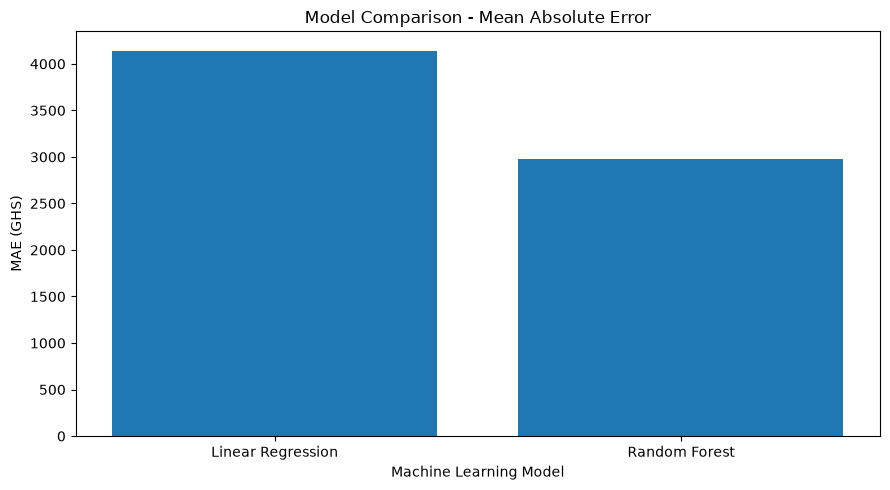

In [17]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (GHS)")

plt.tight_layout()
plt.show()

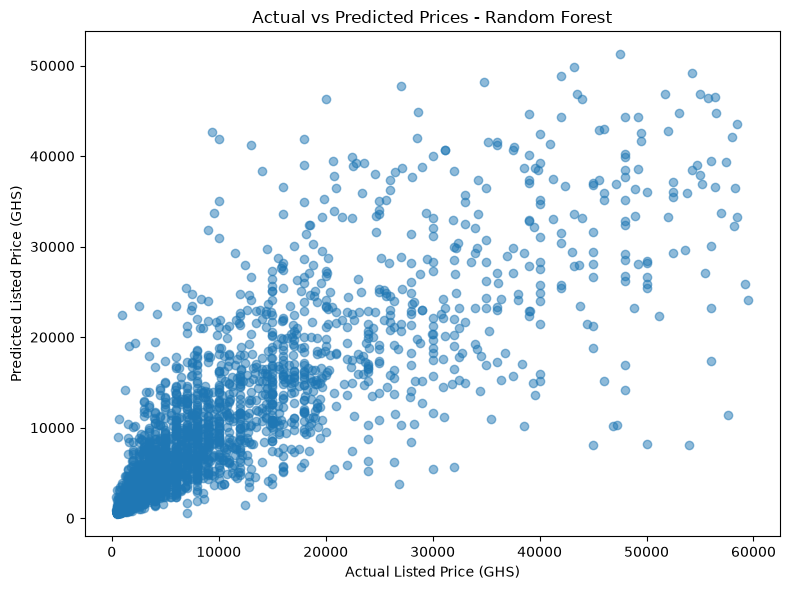

In [18]:
if best_model_name == "Linear Regression":
    best_model = linear_regression_model
    best_predictions = linear_predictions
else:
    best_model = random_forest_model
    best_predictions = random_forest_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Listed Price (GHS)")
plt.ylabel("Predicted Listed Price (GHS)")
plt.title(f"Actual vs Predicted Prices - {best_model_name}")

plt.tight_layout()
plt.show()

In [19]:
METRICS_DIR = Path("../reports/metrics")
METRICS_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = METRICS_DIR / "model_comparison.csv"

results.to_csv(RESULTS_PATH, index=False)

print("Model evaluation results saved!")
print("Saved to:", RESULTS_PATH)

Model evaluation results saved!
Saved to: ..\reports\metrics\model_comparison.csv
